# 🔬 ABLATION STUDY — Kontribusi Fitur Sentimen terhadap Prediksi Volatilitas

Notebook ini menjawab **Rumusan Masalah 1**: *"Bagaimana pengaruh sentimen berita
ekonomi terhadap volatilitas return saham sektor energi LQ45?"*

### Rancangan
Empat model dilatih dengan **prosedur yang identik**; satu-satunya perbedaan adalah
ada/tidaknya 4 fitur sentimen.

| Model | Fitur | Tuning |
|---|---|---|
| XGBoost **DENGAN** sentimen | 17 (13 teknikal + 4 sentimen) | anggaran sama |
| XGBoost **TANPA** sentimen | 13 (teknikal saja) | anggaran sama |
| LSTM **DENGAN** sentimen | 17 | anggaran sama |
| LSTM **TANPA** sentimen | 13 | anggaran sama |

**Setiap konfigurasi di-tuning ulang secara terpisah** dengan anggaran pencarian yang
sama persis. Ini menutup keberatan bahwa *hyperparameter* hasil tuning konfigurasi
17 fitur mungkin menguntungkan salah satu pihak.

### Kendali yang dijaga identik
Data, emiten, split kronologis 80:20, target `Volatilitas_Target` (t+1), normalisasi
(fit pada train saja), `SEED = 42`, ruang pencarian, jumlah iterasi, dan metrik.

### Cara membaca hasil
- Model **tanpa** sentimen **lebih buruk** → sentimen berpengaruh positif (hipotesis terbukti)
- Selisih **tidak berarti** → sentimen tidak menambah informasi di luar fitur teknikal
- Model **tanpa** sentimen **lebih baik** → fitur sentimen menambah derau

**Ketiganya temuan yang sah dan layak dilaporkan.**

> ⏱️ Perkiraan waktu: XGBoost ±20 menit, LSTM ±40 menit.

## CELL 1 — Konfigurasi (disalin identik dari MODEL_xgboost_vv3 & MODEL_lstm__v4)

In [2]:
import os, random, warnings, itertools, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
warnings.filterwarnings('ignore'); os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# ── Reproducibility: identik dgn kedua notebook model ──
SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11, 'figure.dpi': 150})

ROOT = Path.cwd()
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']
KOLOM_Y = 'Volatilitas_Target'

# ── DUA SET FITUR — inilah satu-satunya variabel yang dibedakan ──
KOLOM_X1_TEKNIKAL = [
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
]
KOLOM_X2_SENTIMEN = ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']

SKENARIO = {
    'DENGAN_Sentimen': KOLOM_X1_TEKNIKAL + KOLOM_X2_SENTIMEN,   # 17 fitur
    'TANPA_Sentimen' : KOLOM_X1_TEKNIKAL,                        # 13 fitur
}

# ── Hyperparameter search space: DISALIN PERSIS dari MODEL_xgboost_vv3 CELL 4 ──
PARAM_DIST_XGB = {
    'n_estimators'    : [100, 200, 300, 400],
    'max_depth'       : [4, 5, 6, 7],
    'learning_rate'   : [0.03, 0.05, 0.1, 0.15],
    'subsample'       : [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 2, 3],
    'gamma'           : [0, 0.1, 0.2],
}
N_ITER_TUNING = 25          # identik
TSCV = TimeSeriesSplit(n_splits=5)

# ── Grid LSTM: DISALIN PERSIS dari MODEL_lstm__v4 CELL 4B ──
GRID_LSTM = {'unit1': [16, 32], 'lr': [1e-3], 'dropout': [0.1, 0.2], 'lookback': [10, 15]}
KOMBINASI_LSTM = [dict(zip(GRID_LSTM, v)) for v in itertools.product(*GRID_LSTM.values())]
EPOCHS_TUNE, PATIENCE_TUNE, VAL_FRAC, BATCH_TUNE = 40, 7, 0.15, 32
EPOCHS_FINAL, PATIENCE_FINAL = 100, 15
LOSS_LSTM = 'huber'         # identik
EPS_LOG   = 1e-6

print('=' * 72)
print('  KONFIGURASI ABLATION STUDY')
print('=' * 72)
print(f'  ROOT            : {ROOT}')
print(f'  Target Y        : {KOLOM_Y}')
for nama, kols in SKENARIO.items():
    print(f'  {nama:16}: {len(kols)} fitur')
print(f'  Kombinasi LSTM  : {len(KOMBINASI_LSTM)} | Iterasi XGB: {N_ITER_TUNING}')
print(f'  SEED            : {SEED} (identik dgn notebook model)')
print('=' * 72)

  KONFIGURASI ABLATION STUDY
  ROOT            : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  Target Y        : Volatilitas_Target
  DENGAN_Sentimen : 17 fitur
  TANPA_Sentimen  : 13 fitur
  Kombinasi LSTM  : 8 | Iterasi XGB: 25
  SEED            : 42 (identik dgn notebook model)


## CELL 2 — Fungsi Bantu (identik dengan notebook model)

In [3]:
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """Kembalikan nilai ter-MinMax-scale ke skala asli."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def hitung_mape(y, p, eps=1e-8):
    y = np.asarray(y, float); p = np.asarray(p, float); m = np.abs(y) > eps
    return np.nan if m.sum() == 0 else float(np.mean(np.abs((y[m] - p[m]) / y[m])) * 100)

def evaluasi(y_true, y_pred):
    return {'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'MAE' : float(mean_absolute_error(y_true, y_pred)),
            'MAPE (%)': hitung_mape(y_true, y_pred),
            'R2'  : float(r2_score(y_true, y_pred))}

def buat_sekuens(X, y, lookback):
    X_arr = np.asarray(X, dtype=np.float32); y_arr = np.asarray(y, dtype=np.float32).reshape(-1)
    X_seq = [X_arr[i - lookback:i, :] for i in range(lookback, len(X_arr))]
    y_seq = [y_arr[i] for i in range(lookback, len(X_arr))]
    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.float32)

def buat_model_lstm(n_fitur, lookback, unit1=32, dropout=0.2, lr=1e-3):
    """Arsitektur ringkas v4: LSTM(unit1) -> Dropout -> Dense(1) linear (log-target)."""
    m = Sequential(name='LSTM_Ablation')
    m.add(Input(shape=(lookback, n_fitur)))
    m.add(LSTM(unit1, return_sequences=False))
    m.add(Dropout(dropout))
    m.add(Dense(1, activation='linear'))
    m.compile(optimizer=Adam(learning_rate=lr), loss=LOSS_LSTM)
    return m

print('✅ Fungsi bantu siap (identik dgn MODEL_xgboost_vv3 & MODEL_lstm__v4)')

✅ Fungsi bantu siap (identik dgn MODEL_xgboost_vv3 & MODEL_lstm__v4)


## CELL 3 — Muat Dataset per Emiten

In [4]:
dict_train, dict_test, dict_scaler = {}, {}, {}

for e in URUTAN_EMITEN:
    p_tr = DIR_FINAL / f'dataset_train_{e}.csv'
    p_te = DIR_FINAL / f'dataset_test_{e}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{e}.csv'
    if not (p_tr.exists() and p_te.exists()):
        print(f'  ⚠️  {e}: dataset tidak ditemukan, dilewati'); continue
    dict_train[e] = pd.read_csv(p_tr, encoding='utf-8-sig')
    dict_test[e]  = pd.read_csv(p_te, encoding='utf-8-sig')
    dict_scaler[e] = pd.read_csv(p_sc, index_col=0) if p_sc.exists() else None

    # Validasi: seluruh kolom kedua skenario harus tersedia
    hilang = [c for c in SKENARIO['DENGAN_Sentimen'] + [KOLOM_Y]
              if c not in dict_train[e].columns]
    tanda = '✅' if not hilang else '❌'
    print(f'  {tanda} {e:5}| train={len(dict_train[e]):4} test={len(dict_test[e]):4}'
          + (f' | KOLOM HILANG: {hilang}' if hilang else ''))

print(f'\n  Emiten dimuat: {len(dict_train)}/{len(URUTAN_EMITEN)}')
assert len(dict_train) > 0, 'Tidak ada dataset — jalankan PREP_03 dulu.'

  ✅ ADRO | train= 832 test= 209
  ✅ ADMR | train= 832 test= 209
  ✅ ITMG | train= 832 test= 209
  ✅ PTBA | train= 832 test= 209
  ✅ MEDC | train= 832 test= 209
  ✅ AKRA | train= 832 test= 209
  ✅ PGAS | train= 832 test= 209

  Emiten dimuat: 7/7


## CELL 4 — Ablation XGBoost (tuning ulang tiap skenario)

Setiap skenario di-tuning **terpisah** dengan `RandomizedSearchCV` (25 iterasi,
`TimeSeriesSplit` 5 lipatan) — anggaran identik. Trik skala target ×100 dipertahankan
persis seperti `MODEL_xgboost_vv3` agar hasilnya sebanding.

In [5]:
hasil_xgb_abl = []

print('=' * 72); print('  🌳 ABLATION XGBoost'); print('=' * 72)
for skenario, kolom_x in SKENARIO.items():
    print(f'\n── Skenario: {skenario} ({len(kolom_x)} fitur) ' + '─' * 26)
    for e in URUTAN_EMITEN:
        if e not in dict_train: continue
        kol_wkt = 'Tanggal' if 'Tanggal' in dict_train[e].columns else 'Date'
        df_tr = dict_train[e].sort_values(kol_wkt)
        df_te = dict_test[e].sort_values(kol_wkt)

        X_tr, X_te = df_tr[kolom_x].values, df_te[kolom_x].values
        # Trik skala x100 — IDENTIK dgn MODEL_xgboost_vv3 CELL 4 & 5
        y_tr = df_tr[KOLOM_Y].values * 100
        y_te = df_te[KOLOM_Y].values * 100

        search = RandomizedSearchCV(
            XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1),
            param_distributions=PARAM_DIST_XGB, n_iter=N_ITER_TUNING,
            scoring='neg_root_mean_squared_error', cv=TSCV,
            random_state=SEED, n_jobs=-1, verbose=0)
        search.fit(X_tr, y_tr)

        model = XGBRegressor(objective='reg:squarederror', random_state=SEED,
                             n_jobs=-1, **search.best_params_)
        model.fit(X_tr, y_tr)

        sc = dict_scaler[e]
        y_true = inverse_transform(y_te / 100, sc)
        y_pred = np.clip(inverse_transform(model.predict(X_te) / 100, sc), 0, None)
        m = evaluasi(y_true, y_pred)
        hasil_xgb_abl.append({'Model': 'XGBoost', 'Skenario': skenario,
                              'Emiten': e, 'N_Fitur': len(kolom_x), **m})
        print(f'   {e:5}: RMSE={m["RMSE"]:.5f} | MAPE={m["MAPE (%)"]:6.2f}% | R2={m["R2"]:.4f}')

df_xgb_abl = pd.DataFrame(hasil_xgb_abl)
print('\n✅ Ablation XGBoost selesai.')

  🌳 ABLATION XGBoost

── Skenario: DENGAN_Sentimen (17 fitur) ──────────────────────────
   ADRO : RMSE=0.00258 | MAPE=  7.58% | R2=0.8371
   ADMR : RMSE=0.00483 | MAPE=  8.36% | R2=0.8829
   ITMG : RMSE=0.00189 | MAPE=  9.87% | R2=0.9611
   PTBA : RMSE=0.00243 | MAPE= 16.42% | R2=0.9130
   MEDC : RMSE=0.00305 | MAPE=  6.56% | R2=0.9018
   AKRA : RMSE=0.00222 | MAPE=  7.53% | R2=0.8499
   PGAS : RMSE=0.00376 | MAPE=  8.86% | R2=0.7843

── Skenario: TANPA_Sentimen (13 fitur) ──────────────────────────
   ADRO : RMSE=0.00263 | MAPE=  7.69% | R2=0.8311
   ADMR : RMSE=0.00510 | MAPE=  8.97% | R2=0.8695
   ITMG : RMSE=0.00186 | MAPE=  9.76% | R2=0.9623
   PTBA : RMSE=0.00232 | MAPE= 15.06% | R2=0.9208
   MEDC : RMSE=0.00298 | MAPE=  6.49% | R2=0.9065
   AKRA : RMSE=0.00217 | MAPE=  7.06% | R2=0.8563
   PGAS : RMSE=0.00392 | MAPE=  8.80% | R2=0.7654

✅ Ablation XGBoost selesai.


## CELL 5 — Ablation LSTM (tuning ulang tiap skenario)

Grid identik `MODEL_lstm__v4` CELL 4B: `unit1 ∈ {16,32}`, `dropout ∈ {0.1,0.2}`,
`lookback ∈ {10,15}` (8 kombinasi), Huber loss, **log-target**, arsitektur ringkas
1 lapis. Validasi kronologis 15% terakhir data latih.

In [6]:
hasil_lstm_abl = []

print('=' * 72); print('  🧠 ABLATION LSTM'); print('=' * 72)
for skenario, kolom_x in SKENARIO.items():
    print(f'\n── Skenario: {skenario} ({len(kolom_x)} fitur) ' + '─' * 26)
    for e in URUTAN_EMITEN:
        if e not in dict_train: continue
        kol_wkt = 'Tanggal' if 'Tanggal' in dict_train[e].columns else 'Date'
        df_tr = dict_train[e].sort_values(kol_wkt)
        df_te = dict_test[e].sort_values(kol_wkt)
        sc = dict_scaler[e]

        # LOG-TARGET — identik MODEL_lstm__v4 CELL 4B & 5
        z_tr = np.log(np.clip(inverse_transform(df_tr[KOLOM_Y].values, sc), EPS_LOG, None))
        z_te = np.log(np.clip(inverse_transform(df_te[KOLOM_Y].values, sc), EPS_LOG, None))
        X_tr_raw, X_te_raw = df_tr[kolom_x].values, df_te[kolom_x].values

        # ── Tuning: validasi kronologis (15% terakhir train) ──
        n_val = int(len(X_tr_raw) * VAL_FRAC)
        best, best_rmse = None, np.inf
        for kb in KOMBINASI_LSTM:
            lb = kb['lookback']
            Xs, zs = buat_sekuens(X_tr_raw, z_tr, lb)
            Xf, zf, Xv, zv = Xs[:-n_val], zs[:-n_val], Xs[-n_val:], zs[-n_val:]
            tf.keras.utils.set_random_seed(SEED)
            mdl = buat_model_lstm(len(kolom_x), lb, kb['unit1'], kb['dropout'], kb['lr'])
            mdl.fit(Xf, zf, validation_data=(Xv, zv), epochs=EPOCHS_TUNE,
                    batch_size=BATCH_TUNE, verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE_TUNE,
                                             restore_best_weights=True)])
            zv_pred = mdl.predict(Xv, verbose=0).flatten()
            rmse_v = float(np.sqrt(mean_squared_error(np.exp(zv), np.exp(zv_pred))))
            if rmse_v < best_rmse:
                best_rmse, best = rmse_v, kb

        # ── Latih final dgn hyperparameter terbaik ──
        lb = best['lookback']
        X_seq_tr, z_seq_tr = buat_sekuens(X_tr_raw, z_tr, lb)
        X_seq_te, z_seq_te = buat_sekuens(X_te_raw, z_te, lb)
        tf.keras.utils.set_random_seed(SEED)
        mdl = buat_model_lstm(len(kolom_x), lb, best['unit1'], best['dropout'], best['lr'])
        mdl.fit(X_seq_tr, z_seq_tr, epochs=EPOCHS_FINAL, batch_size=BATCH_TUNE,
                validation_split=VAL_FRAC, verbose=0, shuffle=False,
                callbacks=[EarlyStopping(monitor='val_loss', patience=PATIENCE_FINAL,
                                         restore_best_weights=True)])

        y_true = np.exp(z_seq_te)                                   # inversi = exp()
        y_pred = np.clip(np.exp(mdl.predict(X_seq_te, verbose=0).flatten()), 0, None)
        m = evaluasi(y_true, y_pred)
        hasil_lstm_abl.append({'Model': 'LSTM', 'Skenario': skenario, 'Emiten': e,
                               'N_Fitur': len(kolom_x), 'Lookback': lb, **m})
        print(f'   {e:5}: lb={lb} u={best["unit1"]} do={best["dropout"]} | '
              f'RMSE={m["RMSE"]:.5f} | MAPE={m["MAPE (%)"]:6.2f}% | R2={m["R2"]:.4f}')

df_lstm_abl = pd.DataFrame(hasil_lstm_abl)
print('\n✅ Ablation LSTM selesai.')

  🧠 ABLATION LSTM

── Skenario: DENGAN_Sentimen (17 fitur) ──────────────────────────
   ADRO : lb=15 u=32 do=0.1 | RMSE=0.00460 | MAPE= 14.42% | R2=0.5033
   ADMR : lb=15 u=32 do=0.2 | RMSE=0.00760 | MAPE= 14.19% | R2=0.7237
   ITMG : lb=15 u=32 do=0.1 | RMSE=0.00333 | MAPE= 17.53% | R2=0.8868
   PTBA : lb=10 u=16 do=0.1 | RMSE=0.00456 | MAPE= 29.10% | R2=0.6940
   MEDC : lb=15 u=32 do=0.1 | RMSE=0.00483 | MAPE= 10.96% | R2=0.7667
   AKRA : lb=15 u=32 do=0.2 | RMSE=0.00393 | MAPE= 14.41% | R2=0.5567
   PGAS : lb=15 u=32 do=0.2 | RMSE=0.00494 | MAPE= 13.55% | R2=0.6314

── Skenario: TANPA_Sentimen (13 fitur) ──────────────────────────
   ADRO : lb=15 u=32 do=0.1 | RMSE=0.00420 | MAPE= 13.31% | R2=0.5859
   ADMR : lb=15 u=32 do=0.2 | RMSE=0.00765 | MAPE= 14.80% | R2=0.7203
   ITMG : lb=15 u=32 do=0.1 | RMSE=0.00326 | MAPE= 17.34% | R2=0.8917
   PTBA : lb=15 u=32 do=0.2 | RMSE=0.00415 | MAPE= 26.75% | R2=0.7465
   MEDC : lb=15 u=32 do=0.2 | RMSE=0.00484 | MAPE= 11.26% | R2=0.7659
   AKRA

## CELL 6 — Tabel Selisih (→ Tabel 4.x, jawaban RM-1)

In [7]:
df_abl = pd.concat([df_xgb_abl, df_lstm_abl], ignore_index=True)
df_abl.to_csv(DIR_TABEL / 'tabel_ablation_mentah.csv', index=False, encoding='utf-8-sig')

baris = []
for mdl in ['XGBoost', 'LSTM']:
    for e in URUTAN_EMITEN:
        d = df_abl[(df_abl.Model == mdl) & (df_abl.Emiten == e)]
        if len(d) != 2: continue
        dgn  = d[d.Skenario == 'DENGAN_Sentimen'].iloc[0]
        tanpa = d[d.Skenario == 'TANPA_Sentimen'].iloc[0]
        baris.append({
            'Model': mdl, 'Emiten': e,
            'RMSE_Dengan': dgn['RMSE'], 'RMSE_Tanpa': tanpa['RMSE'],
            'Δ_RMSE_%': (tanpa['RMSE'] - dgn['RMSE']) / tanpa['RMSE'] * 100,
            'MAPE_Dengan': dgn['MAPE (%)'], 'MAPE_Tanpa': tanpa['MAPE (%)'],
            'Δ_MAPE_pp': tanpa['MAPE (%)'] - dgn['MAPE (%)'],
            'R2_Dengan': dgn['R2'], 'R2_Tanpa': tanpa['R2'],
            'Δ_R2': dgn['R2'] - tanpa['R2'],
            'Sentimen_Membantu': 'YA' if dgn['RMSE'] < tanpa['RMSE'] else 'tidak',
        })
df_delta = pd.DataFrame(baris).round(5)
df_delta.to_csv(DIR_TABEL / 'tabel_ablation_sentimen.csv', index=False, encoding='utf-8-sig')

pd.set_option('display.width', 200, 'display.max_columns', 30)
print('=' * 96)
print('  TABEL ABLATION — KONTRIBUSI FITUR SENTIMEN  (Δ positif = sentimen MEMBANTU)')
print('=' * 96)
print(df_delta.to_string(index=False))

print('\n' + '=' * 96); print('  RINGKASAN → JAWABAN RM-1'); print('=' * 96)
for mdl in ['XGBoost', 'LSTM']:
    d = df_delta[df_delta.Model == mdl]
    if not len(d): continue
    n_bantu = (d['Sentimen_Membantu'] == 'YA').sum()
    print(f'\n  {mdl}:')
    print(f'    Sentimen membantu pada     : {n_bantu}/{len(d)} emiten')
    print(f'    Rata-rata Δ RMSE           : {d["Δ_RMSE_%"].mean():+6.2f}%')
    print(f'    Rata-rata Δ MAPE           : {d["Δ_MAPE_pp"].mean():+6.2f} poin persen')
    print(f'    Rata-rata Δ R²             : {d["Δ_R2"].mean():+.4f}')
    rr = d['Δ_RMSE_%'].mean()
    kes = ('sentimen BERPENGARUH POSITIF' if rr > 2 else
           'sentimen TIDAK memberi tambahan informasi berarti' if abs(rr) <= 2 else
           'sentimen justru MENAMBAH DERAU')
    print(f'    → Interpretasi             : {kes}')
print('\n' + '=' * 96)
print('  💾 tabel_ablation_sentimen.csv & tabel_ablation_mentah.csv tersimpan.')
print('=' * 96)

  TABEL ABLATION — KONTRIBUSI FITUR SENTIMEN  (Δ positif = sentimen MEMBANTU)
  Model Emiten  RMSE_Dengan  RMSE_Tanpa  Δ_RMSE_%  MAPE_Dengan  MAPE_Tanpa  Δ_MAPE_pp  R2_Dengan  R2_Tanpa     Δ_R2 Sentimen_Membantu
XGBoost   ADRO      0.00258     0.00263   1.78267      7.57669     7.69491    0.11822    0.83708   0.83111  0.00597                YA
XGBoost   ADMR      0.00483     0.00510   5.26386      8.35986     8.96958    0.60972    0.88287   0.86950  0.01338                YA
XGBoost   ITMG      0.00189     0.00186  -1.62482      9.87221     9.76421   -0.10800    0.96111   0.96234 -0.00123             tidak
XGBoost   PTBA      0.00243     0.00232  -4.76987     16.41644    15.06030   -1.35614    0.91303   0.92077 -0.00774             tidak
XGBoost   MEDC      0.00305     0.00298  -2.50381      6.56202     6.49105   -0.07096    0.90181   0.90655 -0.00474             tidak
XGBoost   AKRA      0.00222     0.00217  -2.22633      7.53470     7.06391   -0.47079    0.84988   0.85635 -0.00647   

## CELL 7 — Grafik Perbandingan (→ Gambar 4.x)

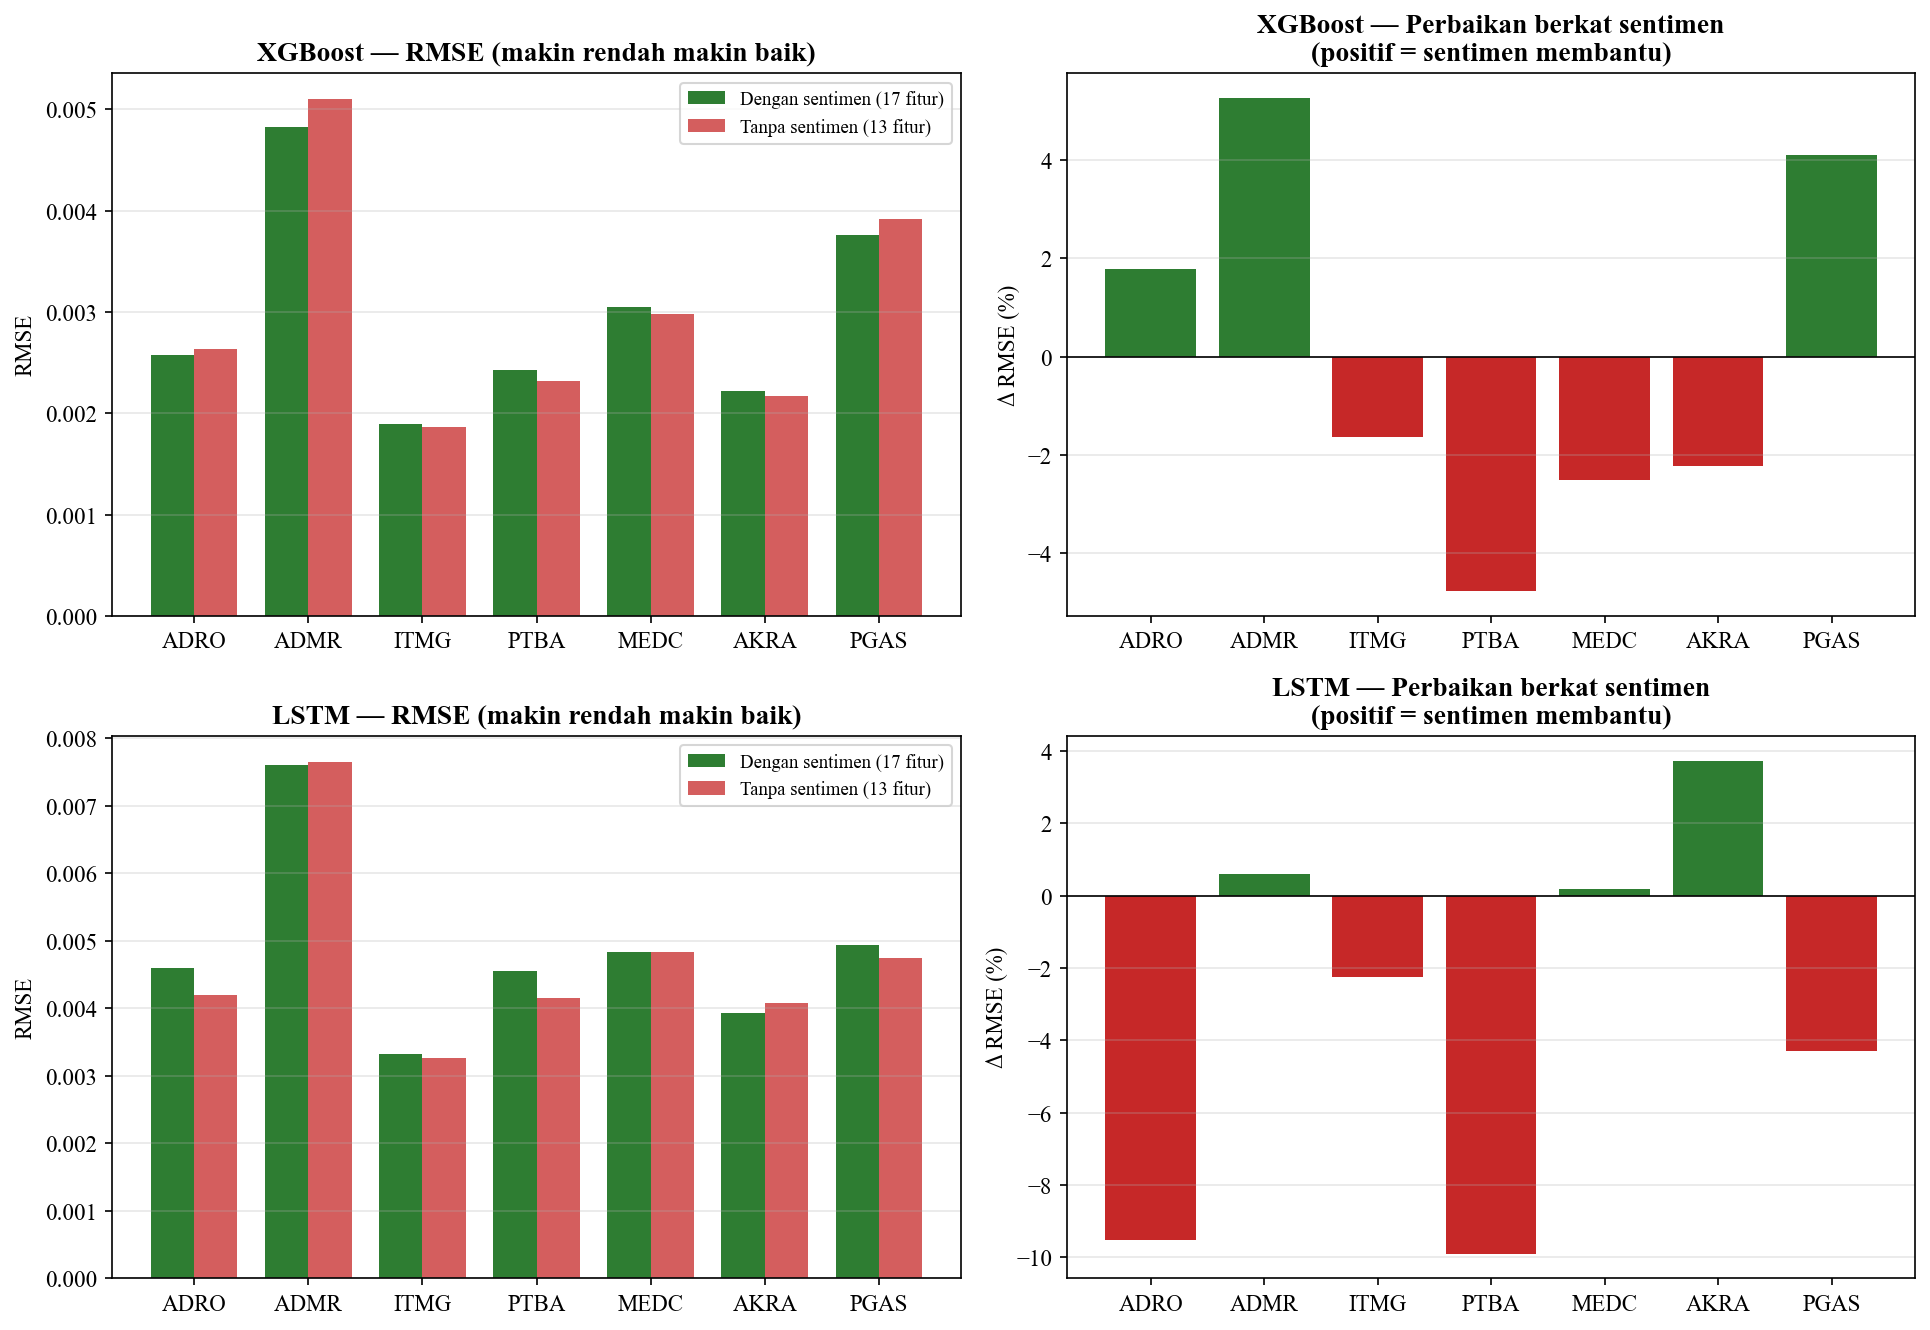

💾 gambar_ablation_sentimen.png tersimpan.


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, mdl in enumerate(['XGBoost', 'LSTM']):
    d = df_delta[df_delta.Model == mdl]
    if not len(d): continue
    x = np.arange(len(d)); w = 0.38
    ax = axes[r, 0]
    ax.bar(x - w/2, d['RMSE_Dengan'], w, label='Dengan sentimen (17 fitur)', color='#2E7D32')
    ax.bar(x + w/2, d['RMSE_Tanpa'],  w, label='Tanpa sentimen (13 fitur)',  color='#C62828', alpha=.75)
    ax.set_xticks(x); ax.set_xticklabels(d['Emiten']); ax.set_ylabel('RMSE')
    ax.set_title(f'{mdl} — RMSE (makin rendah makin baik)', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=.3)

    ax = axes[r, 1]
    warna = ['#2E7D32' if v > 0 else '#C62828' for v in d['Δ_RMSE_%']]
    ax.bar(x, d['Δ_RMSE_%'], color=warna)
    ax.axhline(0, color='k', lw=.8)
    ax.set_xticks(x); ax.set_xticklabels(d['Emiten'])
    ax.set_ylabel('Δ RMSE (%)')
    ax.set_title(f'{mdl} — Perbaikan berkat sentimen\n(positif = sentimen membantu)',
                 fontweight='bold')
    ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_ablation_sentimen.png', dpi=300, bbox_inches='tight')
plt.show()
print('💾 gambar_ablation_sentimen.png tersimpan.')